# MAE 6246 — Week 10: Observing a mass on a pivoted beam
**State observers and output feedback · October 30, 2026**

A motor rotates a beam carrying a sliding mass. We measure **only the beam angle**. Can we estimate the mass position, its velocity, and the beam angular velocity—and use those estimates to stabilize the system?

This notebook follows the physical model and parameters in `Lecture/MassBeam/MassBeam.m`. It uses **pole placement** for both gains, so it requires no LQR or Kalman-filter theory.

Run the cells in order. NumPy, SciPy, and Matplotlib are sufficient; no control-system toolbox is required.

1. Understand the model and sensor.
2. Connect the observability matrix and its null space to physical motions.
3. Design feedback and an observer, then verify separation.
4. Simulate estimation and control with an initially incorrect estimate.
5. Compare observer speeds under measurement noise.
6. Remove a physical coupling and reveal an unobservable subspace.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Arc
from scipy.linalg import null_space, expm
from scipy.signal import place_poles, StateSpace, lsim

np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 11})

## 1. Physical model
Let $d$ be the signed distance of the mass from the pivot and $\theta$ the beam angle, positive counterclockwise from horizontal. The input $u$ is motor torque at the pivot.

Assume a frictionless sliding point mass, a balanced beam, and small deviations about $d=\theta=0$. The linearized equations are

$$
\ddot{d}=-g\theta,\qquad I\ddot\theta=-mgd+u.
$$

A positive beam angle accelerates the mass toward decreasing $d$. A mass on the positive side produces a clockwise gravitational torque. The second effect is essential: **mass position affects the measured angle through the beam acceleration**.

Use $m=1\,\mathrm{kg}$, $I=2\,\mathrm{kg}\,\mathrm{m}^{2}$, and $g=9.81\,\mathrm{m}/\mathrm{s}^{2}$, matching the MATLAB example. Here $I$ is the beam/motor inertia about the pivot at the centered equilibrium. The model neglects friction, actuator limits, and nonlinear terms; predictions are local to small displacements and angles.

Define $x=[d,\dot{d},\theta,\dot\theta]^T$ and measure $y=\theta$. The zero state means a centered mass and horizontal, stationary beam.

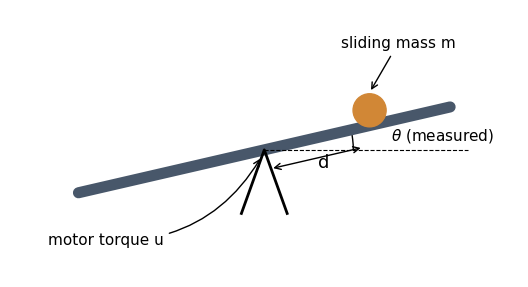

In [4]:
fig, ax = plt.subplots(figsize=(8, 3))
angle = np.deg2rad(13)
e = np.array([np.cos(angle), np.sin(angle)])
a, b = -1.5*e, 1.5*e
ax.plot([a[0], b[0]], [a[1], b[1]], color="#48576a", lw=8,
        solid_capstyle="round")
ax.plot([-0.18, 0, 0.18], [-0.5, 0, -0.5], color="black", lw=2)
p = 0.85*e
ax.add_patch(Circle(p + np.array([0, .12]), .13,
                    color="#d18736", zorder=5))
ax.annotate("sliding mass m", p + [0, .26], xytext=(0.6, .8),
            arrowprops={"arrowstyle": "->"})
ax.annotate("", xy=.80*e+[0,-.16], xytext=.05*e+[0,-.16],
            arrowprops={"arrowstyle": "<->"})
ax.text(.42, -.14, "d", fontsize=13)
ax.plot([0, 1.6], [0, 0], "k--", lw=.8)
ax.add_patch(Arc((0, 0), 1.4, 1.4, theta1=0, theta2=13))
ax.text(1.0, .075, r"$\theta$ (measured)")
ax.annotate("motor torque u", xy=(-.02, -.05), xytext=(-1.7, -.75),
            arrowprops={"arrowstyle": "->", "connectionstyle": "arc3,rad=.3"})
ax.set(xlim=(-2, 2), ylim=(-1, 1.1), aspect="equal")
ax.axis("off"); fig.tight_layout(); plt.show()

In [5]:
m, I, g = 1.0, 2.0, 9.81
A = np.array([[0, 1, 0, 0],
              [0, 0, -g, 0],
              [0, 0, 0, 1],
              [-m*g/I, 0, 0, 0]], dtype=float)
B = np.array([[0], [0], [0], [1/I]], dtype=float)
C = np.array([[0, 0, 1, 0]], dtype=float)
n = A.shape[0]

Ctrb = np.hstack([np.linalg.matrix_power(A, j) @ B for j in range(n)])
O = np.vstack([C @ np.linalg.matrix_power(A, j) for j in range(n)])
print("Open-loop poles:", np.linalg.eigvals(A))
print("Controllability rank:", np.linalg.matrix_rank(Ctrb))
print("Observability matrix:\n", O)
print("Observability rank:", np.linalg.matrix_rank(O))
print("Basis for ker(O), stored as columns:\n", null_space(O))
assert np.linalg.matrix_rank(Ctrb) == n
assert np.linalg.matrix_rank(O) == n

Open-loop poles: [-2.63376+0.j       0.     +2.63376j  0.     -2.63376j  2.63376+0.j     ]
Controllability rank: 4
Observability matrix:
 [[ 0.     0.     1.     0.   ]
 [ 0.     0.     0.     1.   ]
 [-4.905  0.     0.     0.   ]
 [ 0.    -4.905  0.     0.   ]]
Observability rank: 4
Basis for ker(O), stored as columns:
 []


## 2. Why one angle measurement can reveal four states
For this model,

$$
\mathcal{O}=\begin{bmatrix}
0&0&1&0\\0&0&0&1\\-mg/I&0&0&0\\0&-mg/I&0&0
\end{bmatrix}.
$$

It has rank four, so $\ker\mathcal{O}=\{0\}$. The empty basis returned above has shape $(4,0)$: there are no nonzero invisible initial-state differences.

In the ideal model, the information chain is

$$
y=\theta,\quad \dot y=\dot\theta,\quad
\ddot y=-\frac{mg}{I}d+\frac{u}{I},\quad
 y^{(3)}=-\frac{mg}{I}\dot{d}+\frac{\dot u}{I}.
$$

These derivative identities explain observability when the input is known and sufficiently smooth. **We will not differentiate measured data.** The observer uses the model and the residual $y-C\hat{x}$ instead.

The open-loop system has a positive real eigenvalue. Estimation without feedback correction is therefore especially sensitive to initial errors.

## 3. Design the controller and observer
Use

$$
u=-K\hat{x},\qquad
\dot{\hat{x}}=A\hat{x}+Bu+L(y-C\hat{x}).
$$

Choose controller poles $-1,-1.5,-2,-2.5$ and observer poles $-3,-4,-5,-6$. These are illustrative choices, not optimal gains. Observer design uses pole placement for the dual pair $(A^T,C^T)$.

With $e=x-\hat{x}$, the closed loop in $(x,e)$ coordinates is block triangular. Its eight poles must be the four controller poles together with the four observer poles.

In [6]:
controller_poles = np.array([-1., -1.5, -2., -2.5])
observer_poles = np.array([-3., -4., -5., -6.])
K = place_poles(A, B, controller_poles).gain_matrix
L = place_poles(A.T, C.T, observer_poles).gain_matrix.T

# Coordinates in F are [x; xhat], not [x; e].
def combined_matrix(Lgain):
    return np.block([[A, -B @ K],
                     [Lgain @ C, A - B @ K - Lgain @ C]])

F = combined_matrix(L)
expected = np.sort(np.r_[controller_poles, observer_poles])
print("K =", K)
print("L =", L.ravel())
print("Combined poles =", np.sort(np.linalg.eigvals(F)))
np.testing.assert_allclose(np.sort(np.linalg.eigvals(F)), expected, atol=1e-7)

K = [[-11.33905  -3.92457  35.5      14.     ]]
L = [-69.72477 -83.2045   18.      119.     ]
Combined poles = [-6.  -5.  -4.  -3.  -2.5 -2.  -1.5 -1. ]


## 4. Stabilize the beam with an initially incorrect estimate
Start with the mass 8 cm from the pivot and the beam tilted by 2 degrees. Set all estimated states to zero. Only the angle is measured; all feedback commands use $\hat{x}$.

For a comparison, also simulate ideal full-state feedback with the same $K$. The observer-based response need not match it during the estimation transient.

The measurement-noise input enters only the observer. In the exact, noiseless model, $e(t)=e^{(A-LC)t}e(0)$ regardless of the controller gain.

In [7]:
t = np.linspace(0., 12., 6001)
x0 = np.array([0.08, 0., np.deg2rad(2.), 0.])
xhat0 = np.zeros(n)

# nu is noise added to the measured beam angle, in radians.
def simulate(Lgain, nu=None, initial_estimate=None):
    if nu is None:
        nu = np.zeros_like(t)
    if initial_estimate is None:
        initial_estimate = xhat0
    Fgain = combined_matrix(Lgain)
    Gnu = np.vstack([np.zeros((n, 1)), Lgain])
    system = StateSpace(Fgain, Gnu, np.eye(2*n), np.zeros((2*n, 1)))
    _, Z, _ = lsim(system, U=nu, T=t, X0=np.r_[x0, initial_estimate])
    X, Xhat = Z[:, :n], Z[:, n:]
    U = -(Xhat @ K.T).ravel()
    return X, Xhat, U

X, Xhat, U = simulate(L)
E = X - Xhat
ideal_sys = StateSpace(A-B@K, np.zeros((n, 1)), np.eye(n), np.zeros((n, 1)))
_, Xideal, _ = lsim(ideal_sys, U=np.zeros_like(t), T=t, X0=x0)
for j in [0, 100, 500, 2000, 6000]:
    np.testing.assert_allclose(E[j], expm((A-L@C)*t[j]) @ (x0-xhat0), atol=1e-9)
assert np.linalg.norm(E[-1]) < 1e-8
assert np.linalg.norm(X[-1]) < 2e-4
print("Peak torque [N m]:", np.max(np.abs(U)))
print("Peak mass displacement [m]:", np.max(np.abs(X[:, 0])))
print("Peak beam angle [deg]:", np.rad2deg(np.max(np.abs(X[:, 2]))))
print("Final state:", X[-1])

Peak torque [N m]: 3.725306198691271
Peak mass displacement [m]: 0.1620218653117066
Peak beam angle [deg]: 3.05159001139879
Final state: [-0.00009  0.00009  0.00001 -0.00001]


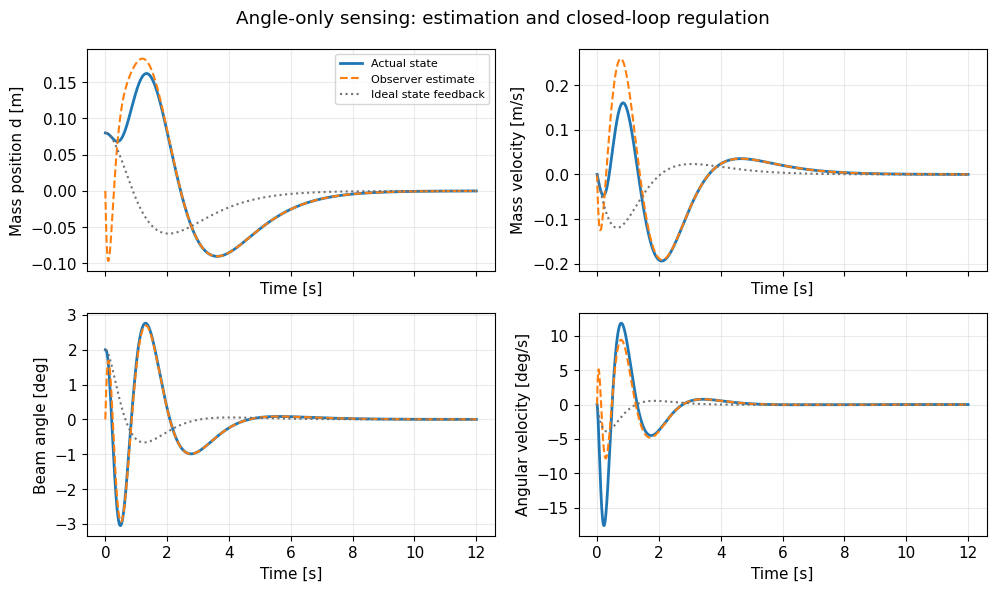

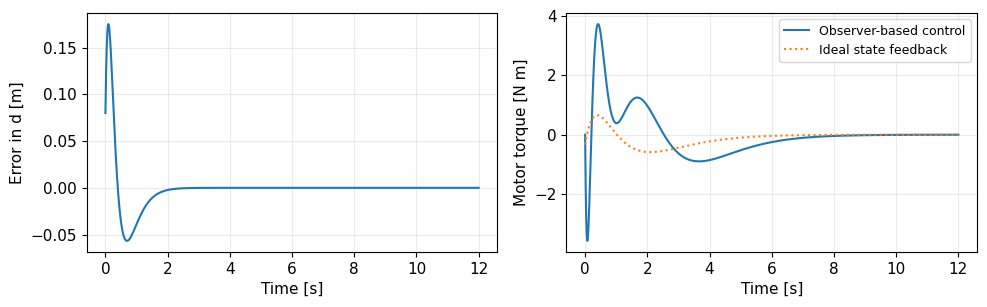

In [8]:
labels = ["Mass position d [m]", "Mass velocity [m/s]",
          "Beam angle [deg]", "Angular velocity [deg/s]"]
scale = np.array([1., 1., 180/np.pi, 180/np.pi])
fig, axs = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
for j, ax in enumerate(axs.ravel()):
    ax.plot(t, X[:, j]*scale[j], label="Actual state", lw=2)
    ax.plot(t, Xhat[:, j]*scale[j], "--", label="Observer estimate")
    ax.plot(t, Xideal[:, j]*scale[j], ":", color="0.45", label="Ideal state feedback")
    ax.set_ylabel(labels[j]); ax.set_xlabel("Time [s]")
axs[0, 0].legend(fontsize=8)
fig.suptitle("Angle-only sensing: estimation and closed-loop regulation")
fig.tight_layout(); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
axs[0].plot(t, E[:, 0], label="Position estimation error")
axs[0].set(xlabel="Time [s]", ylabel="Error in d [m]")
axs[1].plot(t, U, label="Observer-based control")
axs[1].plot(t, -(Xideal@K.T).ravel(), ":", label="Ideal state feedback")
axs[1].set(xlabel="Time [s]", ylabel="Motor torque [N m]")
axs[1].legend(fontsize=9); fig.tight_layout(); plt.show()

**Discuss:** The actual mass first moves away from the center before returning. The initial estimate was wrong, so early feedback commands differ from full-state feedback. Stable poles guarantee eventual decay in this linear model; they do not eliminate transient peaks.

## 5. Faster estimation versus sensor noise
Double the observer-pole magnitudes while retaining the controller gain. To isolate the noise effect, start with the correct estimate in both runs and use the same angle noise:

$$
\nu(t)=0.02\frac{\pi}{180}\,[\sin(40t)+\sin(110t)].
$$

Each sinusoid has amplitude 0.02 degrees. This is a deterministic demonstration rather than a stochastic noise model. The error equation is $\dot{e}=(A-LC)e-L\nu$.

Compare state errors component by component: their physical units differ, so an unscaled four-state norm is not a unit-independent performance measure.

Baseline L: [-69.72477 -83.2045   18.      119.     ]
Faster L: [ -557.79817 -1184.12193    36.        476.     ]
RMS estimation errors after 3 seconds:
Mass position d [m]         baseline=0.00044544, faster=0.00333508
Mass velocity [m/s]         baseline=0.000528567, faster=0.00705906
Beam angle [deg]            baseline=0.00660496, faster=0.0123953
Angular velocity [deg/s]    baseline=0.0436174, faster=0.163279


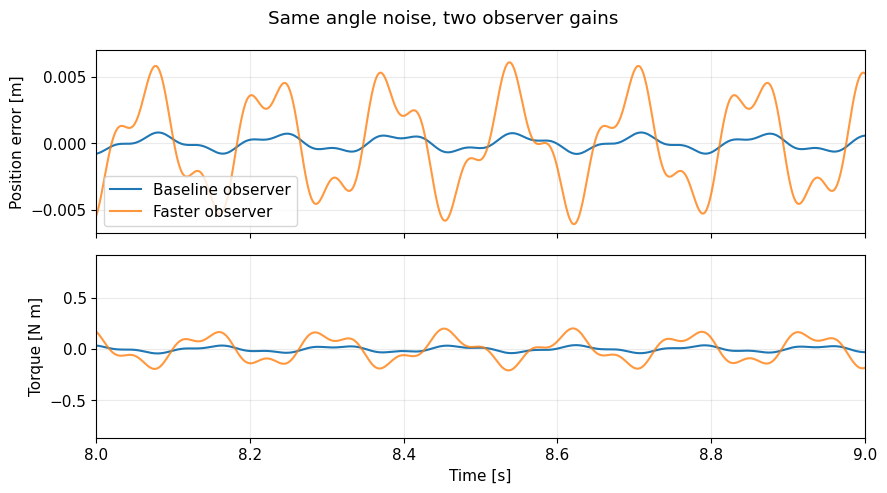

In [9]:
Lfast = place_poles(A.T, C.T, 2*observer_poles).gain_matrix.T
nu = np.deg2rad(0.02) * (np.sin(40*t) + np.sin(110*t))
Xn, Xhn, Un = simulate(L, nu, x0)
Xf, Xhf, Uf = simulate(Lfast, nu, x0)
En, Ef = Xn-Xhn, Xf-Xhf
mask = t >= 3
print("Baseline L:", L.ravel())
print("Faster L:", Lfast.ravel())
print("RMS estimation errors after 3 seconds:")
for j, label in enumerate(labels):
    a = np.sqrt(np.mean(En[mask, j]**2))*scale[j]
    b = np.sqrt(np.mean(Ef[mask, j]**2))*scale[j]
    print(f"{label:27s} baseline={a:.6g}, faster={b:.6g}")

fig, axs = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
axs[0].plot(t, En[:, 0], label="Baseline observer")
axs[0].plot(t, Ef[:, 0], label="Faster observer", alpha=.8)
axs[0].set_ylabel("Position error [m]"); axs[0].legend()
axs[1].plot(t, Un, label="Baseline observer")
axs[1].plot(t, Uf, label="Faster observer", alpha=.8)
axs[1].set(xlim=(8, 9), xlabel="Time [s]", ylabel="Torque [N m]")
fig.suptitle("Same angle noise, two observer gains")
fig.tight_layout(); plt.show()

## 6. Make an unobservable subspace appear
Suppose a simplified model neglects the gravitational torque that the displaced mass applies to the beam. This is a **different model**, not a coordinate change:

$$
\ddot{d}=-g\theta,\qquad I\ddot\theta=u.
$$

Only $A_{4,1}$ changes, from $-mg/I$ to zero. Now angle and angular velocity evolve independently of mass position and velocity. With the same angle-only sensor,

$$
\mathcal{O}_{\mathrm{simplified}}=
\begin{bmatrix}0&0&1&0\\0&0&0&1\\0&0&0&0\\0&0&0&0\end{bmatrix},
\qquad
\ker\mathcal{O}_{\mathrm{simplified}}=\operatorname{span}\{e_1,e_2\}.
$$

Two initial states differing only in mass position or velocity are indistinguishable under the same input. The unobservable block is a double integrator, with poles at zero. Therefore the simplified pair is **not detectable**, and no angle-only observer gain can make all errors converge.

The following compares two zero-input trajectories whose initial difference lies in that null space. Their measured angles are identical, while their mass positions differ.

Simplified observability rank: 2
Basis for its unobservable subspace:
 [[1. 0.]
 [0. 1.]
 [0. 0.]
 [0. 0.]]


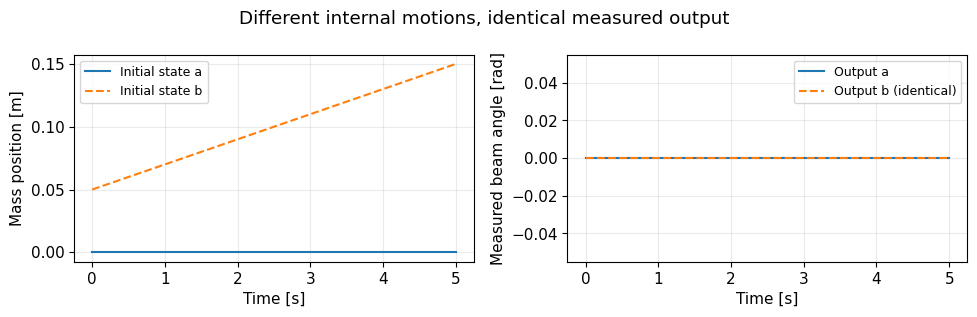

In [10]:
Asimple = A.copy()
Asimple[3, 0] = 0.
Osimple = np.vstack([C@np.linalg.matrix_power(Asimple, j) for j in range(n)])
N = null_space(Osimple)
print("Simplified observability rank:", np.linalg.matrix_rank(Osimple))
print("Basis for its unobservable subspace:\n", N)
assert N.shape == (4, 2)
np.testing.assert_allclose(Osimple@N, 0, atol=1e-12)
np.testing.assert_allclose((np.eye(4)-N@N.T)@Asimple@N, 0, atol=1e-12)

eta = np.array([0.05, 0.02, 0., 0.])  # Invisible position/velocity difference
np.testing.assert_allclose(Osimple@eta, 0)
ta = np.linspace(0, 5, 501)
Xa = np.zeros((len(ta), 4))
Xb = np.array([expm(Asimple*ti)@eta for ti in ta])
Ya, Yb = (Xa@C.T).ravel(), (Xb@C.T).ravel()
np.testing.assert_allclose(Ya, Yb, atol=1e-12)
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
axs[0].plot(ta, Xa[:, 0], label="Initial state a")
axs[0].plot(ta, Xb[:, 0], "--", label="Initial state b")
axs[0].set(xlabel="Time [s]", ylabel="Mass position [m]")
axs[1].plot(ta, Ya, label="Output a")
axs[1].plot(ta, Yb, "--", label="Output b (identical)")
axs[1].set(xlabel="Time [s]", ylabel="Measured beam angle [rad]")
for ax in axs: ax.legend(fontsize=9)
fig.suptitle("Different internal motions, identical measured output")
fig.tight_layout(); plt.show()

## Discussion and extensions
1. Why can the original angle sensor reveal the mass position even though it does not measure it directly?
2. Which row of the original observability matrix carries information about $d$? About $\dot{d}$?
3. Replace the sensor by a mass-position sensor $C=[1,0,0,0]$. Test both models. Does the simplified model remain unobservable?
4. Set $\hat{x}(0)=x(0)$ and remove noise. Verify that observer-based feedback matches ideal state feedback.
5. Increase the initial angle or impose a torque limit. Which assumptions behind the linear simulation and separation result need to be reconsidered?

**Expected observations:** In question 3, both models are observable from mass position: its second derivative reveals angle, and its third derivative reveals angular velocity. In question 4, zero error remains zero. With saturation, the observer should receive the actual applied torque; the linear separation theorem alone does not establish nonlinear closed-loop stability.

**MATLAB connection:** `Lecture/MassBeam/MassBeam.m` supplies the four-state model, $m=1$, $I=2$, and angle-only output. Its `lqr` designs are replaced here by `place_poles`; the observer is implemented using the same duality. `Lecture/MassBeam/2013/SimMassBeam_Observer.mdl` is an earlier observer simulation. This notebook focuses on the linear model and does not port the nonlinear Simulink blocks.